In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Visual settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

# Load datasets
orders = pd.read_csv("olist_orders_dataset.csv")
reviews = pd.read_csv("olist_order_reviews_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
payments = pd.read_csv("olist_order_payments_dataset.csv")

print("Files successfully loaded!")

Files successfully loaded!


In [2]:
# Convert columns to datetime
date_cols = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in date_cols:
  orders[col] = pd.to_datetime(orders[col])

# Filter only delivered orders with valid delivery dates
df = orders[orders["order_status"] == "delivered"].dropna(
    subset=["order_delivered_customer_date"]
).copy()

# Feature 1: Actual delivery duration in days
df["actual_delivery_days"] = (
    df["order_delivered_customer_date"] - df["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Feature 2: Delay compared to estimated date
df["delay_vs_estimated"] = (
    df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]
).dt.total_seconds() / 86400
df["is_delayed"] = df["delay_vs_estimated"] > 0

# Merge reviews & customers
df = df.merge(reviews[["order_id", "review_score"]], on="order_id", how="inner")
df = df.merge(
    customers[["customer_id", "customer_unique_id", "customer_state"]],
    on="customer_id",
    how="inner",
)

# Merge revenue per order
order_rev = payments.groupby("order_id")["payment_value"].sum().reset_index()
df = df.merge(order_rev, on="order_id", how="left")

# Print Key Metrics for Presentation
print("=" * 45)
print("     KEY METRICS SUMMARY FOR PRESENTATION    ")
print("=" * 45)
print(f"Total Delivered Orders  : {df['order_id'].nunique():,}")
print(f"Total Revenue           : R$ {df['payment_value'].sum():,.2f}")
print(f"Average Delivery Time   : {df['actual_delivery_days'].mean():.1f} Days")
print(f"Delayed Orders %        : {(df['is_delayed'].mean() * 100):.1f}%")
print(
    f"Avg Rating (On-Time)    : {df[~df['is_delayed']]['review_score'].mean():.2f} / 5.0"
)
print(
    f"Avg Rating (Delayed)    : {df[df['is_delayed']]['review_score'].mean():.2f} / 5.0"
)
repeat_cust = (
    (df["customer_unique_id"].value_counts() > 1).sum()
    / df["customer_unique_id"].nunique()
) * 100
print(f"Repeat Customer Rate    : {repeat_cust:.2f}%")
print("=" * 45)

     KEY METRICS SUMMARY FOR PRESENTATION    
Total Delivered Orders  : 95,824
Total Revenue           : R$ 15,362,543.99
Average Delivery Time   : 12.5 Days
Delayed Orders %        : 8.0%
Avg Rating (On-Time)    : 4.29 / 5.0
Avg Rating (Delayed)    : 2.57 / 5.0
Repeat Customer Rate    : 3.08%


C:\Users\SAURABH KUMAR SINGH\AppData\Local\Temp\ipykernel_11868\772251804.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(
C:\Users\SAURABH KUMAR SINGH\AppData\Local\Temp\ipykernel_11868\772251804.py:22: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout()


C:\Users\SAURABH KUMAR SINGH\AppData\Local\Temp\ipykernel_11868\772251804.py:23: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.savefig("chart1_delay_vs_rating.png", dpi=300)


C:\Users\SAURABH KUMAR SINGH\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


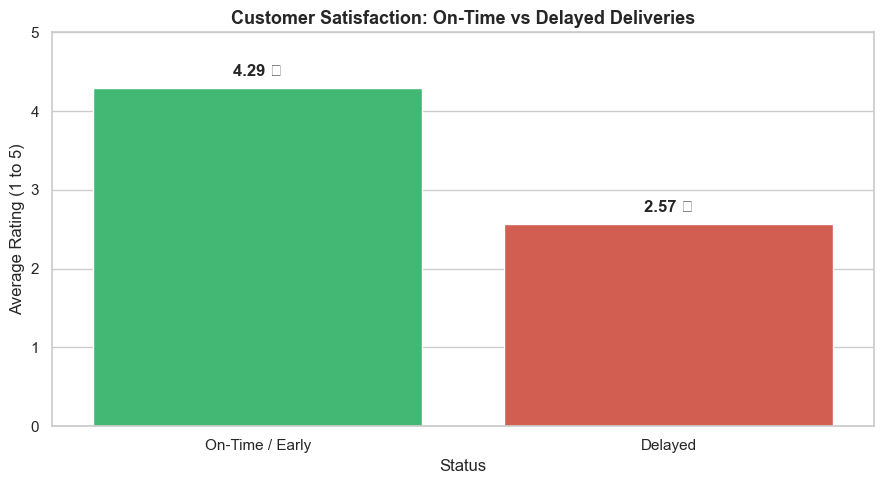

C:\Users\SAURABH KUMAR SINGH\AppData\Local\Temp\ipykernel_11868\772251804.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="review_score", palette="Blues_r")


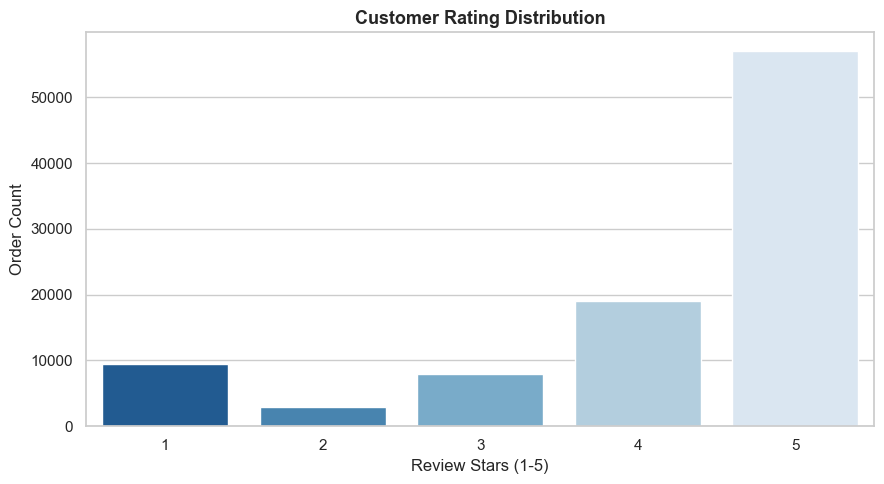

C:\Users\SAURABH KUMAR SINGH\AppData\Local\Temp\ipykernel_11868\772251804.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


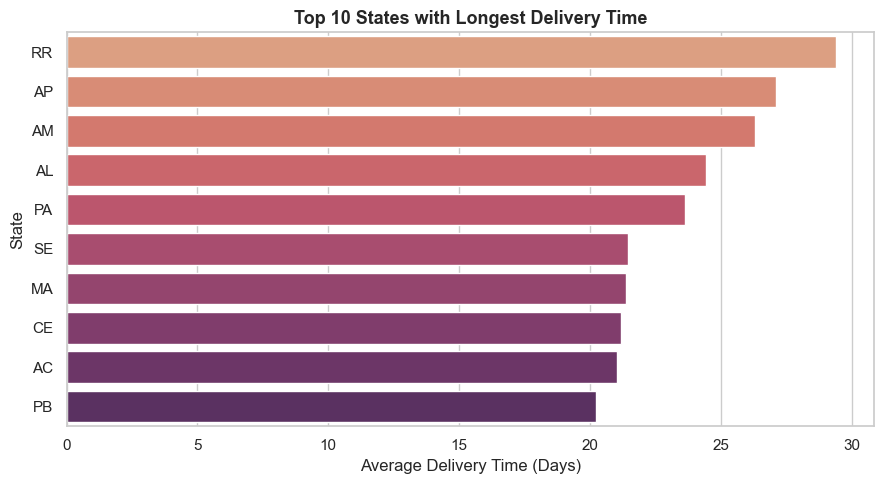

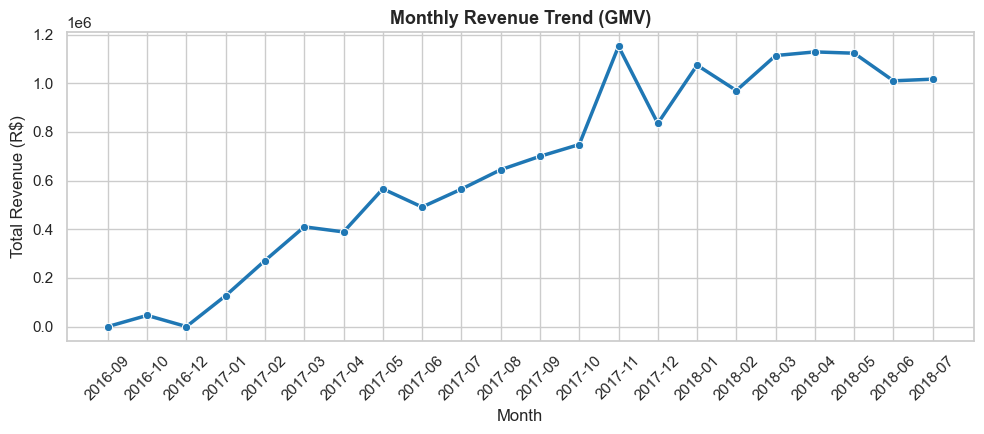

In [3]:
# 1. Delay vs Rating Barplot
plt.figure()
delay_summary = df.groupby("is_delayed")["review_score"].mean().reset_index()
delay_summary["Status"] = delay_summary["is_delayed"].map(
    {False: "On-Time / Early", True: "Delayed"}
)
ax1 = sns.barplot(
    data=delay_summary,
    x="Status",
    y="review_score",
    palette=["#2ecc71", "#e74c3c"],
)
plt.title(
    "Customer Satisfaction: On-Time vs Delayed Deliveries",
    fontsize=13,
    weight="bold",
)
plt.ylabel("Average Rating (1 to 5)")
plt.ylim(0, 5)
for i, v in enumerate(delay_summary["review_score"]):
  plt.text(i, v + 0.15, f"{v:.2f} ★", ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig("chart1_delay_vs_rating.png", dpi=300)
plt.show()

# 2. Rating Breakdown
plt.figure()
sns.countplot(data=df, x="review_score", palette="Blues_r")
plt.title("Customer Rating Distribution", fontsize=13, weight="bold")
plt.xlabel("Review Stars (1-5)")
plt.ylabel("Order Count")
plt.tight_layout()
plt.savefig("chart2_review_distribution.png", dpi=300)
plt.show()

# 3. Top 10 Slowest States
plt.figure()
slowest = (
    df.groupby("customer_state")["actual_delivery_days"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
sns.barplot(
    data=slowest, x="actual_delivery_days", y="customer_state", palette="flare"
)
plt.title("Top 10 States with Longest Delivery Time", fontsize=13, weight="bold")
plt.xlabel("Average Delivery Time (Days)")
plt.ylabel("State")
plt.tight_layout()
plt.savefig("chart3_slowest_states.png", dpi=300)
plt.show()

# 4. Monthly Revenue Trend
df["month"] = df["order_purchase_timestamp"].dt.to_period("M").astype(str)
monthly = df.groupby("month")["payment_value"].sum().reset_index().iloc[:-1]
plt.figure(figsize=(10, 4.5))
sns.lineplot(
    data=monthly,
    x="month",
    y="payment_value",
    marker="o",
    color="#1f77b4",
    linewidth=2.5,
)
plt.xticks(rotation=45)
plt.title("Monthly Revenue Trend (GMV)", fontsize=13, weight="bold")
plt.xlabel("Month")
plt.ylabel("Total Revenue (R$)")
plt.tight_layout()
plt.savefig("chart4_monthly_revenue.png", dpi=300)
plt.show()